# Morphology (형태학)에 사용되는 침식, 팽창, 반복해서 침식-팽창, 팽창-침식

In [15]:
# 공통부분이기 때문에 실습을 새로운 notebook에서 할때마다 복사해서 실행
import sys
sys.path.append('../multi_info/common') # 모듈이 존재하는 path를 추가
import cvnb
import cv2
import numpy as np
import matplotlib.pyplot as plt

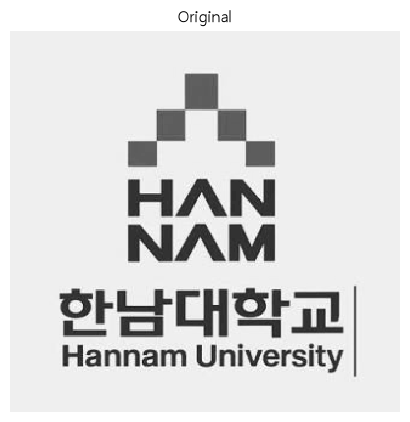

In [16]:
hnu_symbol = cv2.imread("../multi_info/images/hnu_symbol.png", cv2.IMREAD_GRAYSCALE)
if hnu_symbol is None: raise Exception("영상 파일 읽기 오류")
cv2.imshow("Original", hnu_symbol)

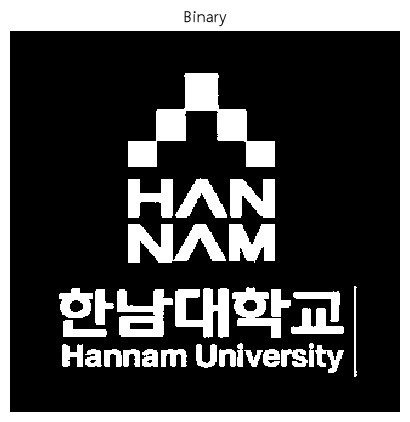

In [17]:
th_img = cv2.threshold(hnu_symbol, 200, 255, cv2.THRESH_BINARY_INV)[1]
cv2.imshow("Binary", th_img)

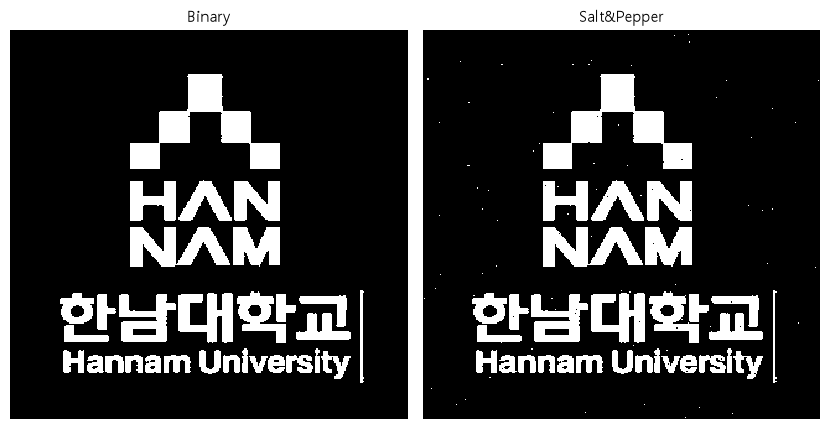

In [18]:
th_img = cv2.threshold(hnu_symbol, 200, 255, cv2.THRESH_BINARY_INV)[1]
cv2.imshow("Binary", th_img)
n = 200
h, w = th_img.shape[:2]
x, y = np.random.randint(0, w, n), np.random.randint(0, h, n)
for (x,y) in zip(x,y):
    th_img[y,x] = 0 if np.random.rand() < 0.5 else 255
cv2.imshow("Salt&Pepper", th_img)

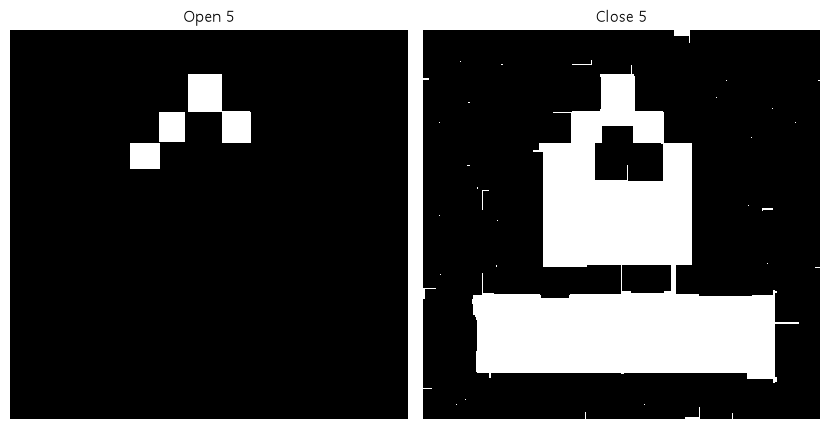

In [20]:
open5 = cv2.morphologyEx(th_img, cv2.MORPH_OPEN, mask, iterations=10)
close5 = cv2.morphologyEx(th_img, cv2.MORPH_CLOSE, mask, iterations=10)
cv2.imshow("Open 5", open5)
cv2.imshow("Close 5", close5)

# 자동차 번호판 추출하는 과정

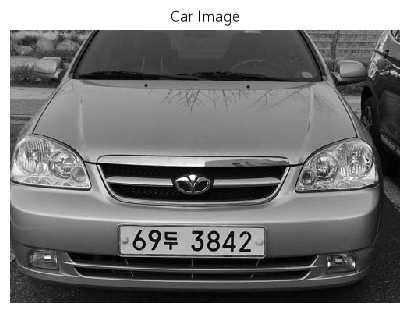

In [21]:
car_img = cv2.imread("../multi_info/images/car/00.jpg", cv2.IMREAD_GRAYSCALE)
if car_img is None: raise Exception("영상 파일 오류")
cv2.imshow("Car Image", car_img)

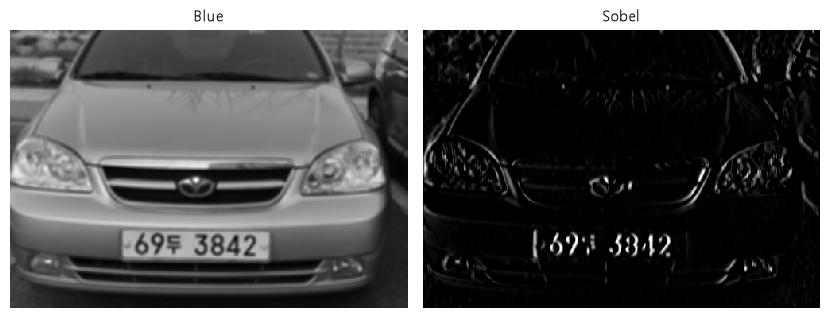

In [27]:
blur = cv2.blur(car_img, (5,5))
sobelx = cv2.Sobel(blur, cv2.CV_8U, 1, 0, 5) # y쪽 방향으로 edge가 검출 (강조)
sobely = cv2.Sobel(blur, cv2.CV_8U, 0, 1, 5) # x쪽 방향으로 edge가 강조
sobel = sobelx #cv2.addWeighted(sobelx, 0.5, sobely, 0.5, 0) # y쪽 방향을 강조하는 것이 번호판 추출에 이점
cv2.imshow("Blue", blur)
cv2.imshow("Sobel", sobel)

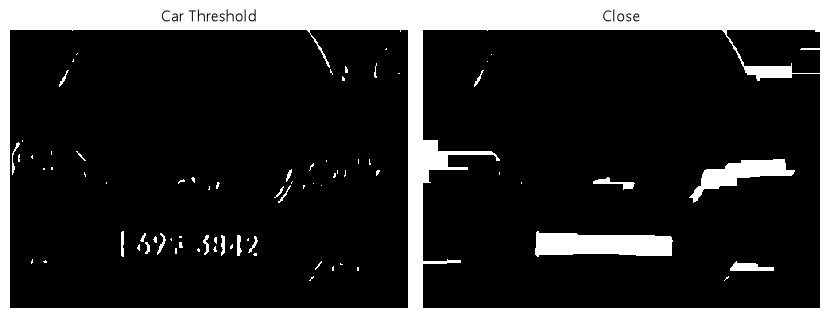

In [28]:
mask_pl = np.ones((5, 20), np.uint8)
car_th = cv2.threshold(sobel, 120, 255, cv2.THRESH_BINARY)[1]
morph = cv2.morphologyEx(car_th, cv2.MORPH_CLOSE, mask_pl, iterations=3)
cv2.imshow("Car Threshold", car_th)
cv2.imshow("Close", morph)